<div style="color:#3c4d5a; border-top: 7px solid #42A5F5; border-bottom: 7px solid #42A5F5; padding: 5px; text-align: center; text-transform: uppercase"><h1>Predicción de inventario y stock de un supermercado</h1> </div>

El inventario disponible cambia con las ventas y las reposiciones. Conocer cuánto stock quedará en una fecha futura ayuda a identificar productos que pueden agotarse y a planificar su abastecimiento.

En esta práctica se desarrolla una red neuronal recurrente LSTM para **predecir directamente el stock al cierre del día**. Se utilizan 10 productos y 60 días de ventas sintéticas. Las cantidades, existencias y fechas festivas corresponden a un escenario de simulación.

#### OBJETIVO GENERAL

Desarrollar y evaluar una red LSTM que estime el stock futuro de los productos de un supermercado a partir de su historial.

#### OBJETIVOS ESPECÍFICOS

- Preparar los archivos de ventas e inventario y analizar la distribución y evolución temporal de sus variables.
- Crear características de calendario y variables combinadas, y construir secuencias por producto.
- Comparar el error antes y después de la ingeniería de características mediante MSE y RMSE, y ajustar la ventana temporal con validación.
- Implementar una función que devuelva el stock de un producto y otra que devuelva un vector con el stock de todos los productos para una fecha.

El desarrollo se organiza en las siguientes secciones:

- [Preparación de datos](#Preparacion)
- [Desarrollo de la RNN](#RNN)
- [Conclusiones](#Conclusiones)
- [Referencias](#Referencias)

<div id="Preparacion" style="color:#37475a; border-bottom: 7px solid orange; width: 100%; margin-bottom: 15px; padding-bottom: 2px"><h2>Preparación de datos</h2> </div>

#### PREPARACIÓN DEL ENTORNO

Se importan las bibliotecas necesarias para manejar los datos, elaborar los gráficos y entrenar la red. La semilla 42 permite reproducir la generación del dataset y controlar la inicialización de los modelos. Las celdas deben ejecutarse en orden.

La práctica puede desarrollarse en Jupyter o Google Colab. Para este volumen de datos es suficiente una CPU; en Colab también se puede seleccionar GPU desde la configuración del entorno de ejecución. Si falta alguna biblioteca, se puede ejecutar la instrucción de instalación incluida al inicio del código.

In [1]:
# En Colab o Jupyter, ejecutar solo si faltan estas bibliotecas:
# %pip install tensorflow==2.20.0 pandas numpy matplotlib scikit-learn joblib

import os
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"
os.environ["TF_ENABLE_ONEDNN_OPTS"] = "0"
os.environ["TF_DETERMINISTIC_OPS"] = "1"

from pathlib import Path
import json
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import tensorflow as tf
import sklearn
import joblib
from IPython.display import display, Markdown
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_squared_error
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, LSTM, Dense
from tensorflow.keras.callbacks import EarlyStopping

SEMILLA = 42
tf.keras.utils.set_random_seed(SEMILLA)
tf.config.threading.set_inter_op_parallelism_threads(2)
tf.config.threading.set_intra_op_parallelism_threads(2)
tf.config.experimental.enable_op_determinism()

DATA = Path("data")
RESULTADOS = Path("resultados")
GRAFICOS = RESULTADOS / "graficos"
TABLAS = RESULTADOS / "tablas"
MODELOS = Path("modelos")
for carpeta in (DATA, GRAFICOS, TABLAS, MODELOS):
    carpeta.mkdir(parents=True, exist_ok=True)

plt.rcParams.update({"figure.dpi": 110, "font.size": 10, "axes.grid": True,
                     "grid.alpha": 0.25, "axes.spines.top": False,
                     "axes.spines.right": False})

def guardar_grafico(nombre):
    plt.tight_layout()
    plt.savefig(GRAFICOS / f"{nombre}.png", bbox_inches="tight")
    plt.show()
    plt.close()

print("TensorFlow:", tf.__version__, "| pandas:", pd.__version__)
print("NumPy:", np.__version__, "| scikit-learn:", sklearn.__version__)
print("GPU disponibles:", len(tf.config.list_physical_devices("GPU")))

TensorFlow: 2.20.0 | pandas: 3.0.1
NumPy: 2.3.5 | scikit-learn: 1.9.1
GPU disponibles: 0


#### GENERACIÓN DEL DATASET SINTÉTICO

Se generan ventas del **1 de enero al 1 de marzo de 2026**, ambos incluidos. Cada producto tiene una venta base, variación aleatoria y un pequeño crecimiento. Los fines de semana y cuatro feriados hipotéticos modifican las ventas del escenario.

| Archivo | Variables |
|---|---|
| `data/inventory.csv` | `product_id`, `nombre`, `categoria`, `unidad`, `stock_actual`, `fecha_expiracion` |
| `data/sales_history.csv` | `product_id`, `nombre`, `fecha_venta`, `cantidad_vendida`, `stock_en_momento` |

Una botella, paquete o pieza representa una unidad comercial. Cada mañana se repone hasta cuatro veces la venta base. `stock_en_momento` es el inventario antes de vender y `stock_actual` es el saldo al cierre del último día. El stock inicial de cada producto permanece fijo, mientras que el de cierre cambia con las ventas.

Después de cargar los CSV se obtiene **`stock_cierre = stock_en_momento - cantidad_vendida`**, que será la variable objetivo de la red. Esta columna se calcula dentro del cuaderno sin cambiar la estructura de los CSV.

Los feriados del escenario son el 6 y el 26 de enero, y el 16 y el 25 de febrero. Son hipotéticos; para un supermercado real se necesitaría el calendario de su ubicación. La fecha de expiración describe el lote disponible en el último cierre. No existe un historial de vencimientos de los lotes que se reponen cada día.

In [2]:
FERIADOS = pd.to_datetime(["2026-01-06", "2026-01-26", "2026-02-16", "2026-02-25"])
fechas = pd.date_range("2026-01-01", periods=60, freq="D")
catalogo = pd.DataFrame([
    ("P001", "Leche en botella", "Lácteos", 24, 7),
    ("P002", "Yogur individual", "Lácteos", 18, 14),
    ("P003", "Pan empacado", "Panadería", 30, 5),
    ("P004", "Arroz en paquete", "Abarrotes", 20, 180),
    ("P005", "Azúcar en paquete", "Abarrotes", 15, 180),
    ("P006", "Aceite en botella", "Abarrotes", 22, 180),
    ("P007", "Atún en lata", "Abarrotes", 16, 365),
    ("P008", "Agua en botella", "Bebidas", 28, 180),
    ("P009", "Jugo en caja", "Bebidas", 35, 90),
    ("P010", "Detergente en bolsa", "Limpieza", 12, 365),
], columns=["product_id", "nombre", "categoria", "venta_base", "vida_lote_dias"])

rng = np.random.default_rng(SEMILLA)
filas_ventas, filas_inventario = [], []
for producto in catalogo.itertuples(index=False):
    for dia, fecha in enumerate(fechas):
        fin_semana = int(fecha.dayofweek >= 5)
        feriado = int(fecha in FERIADOS)
        venta_esperada = (producto.venta_base * (1 + 0.40 * fin_semana + 0.60 * feriado)
                   + 0.04 * dia + rng.normal(0, 2))
        stock_inicio = int(producto.venta_base * 4)
        cantidad = min(stock_inicio, max(0, int(round(venta_esperada))))
        filas_ventas.append([producto.product_id, producto.nombre, fecha,
                             cantidad, stock_inicio])
    filas_inventario.append([
        producto.product_id, producto.nombre, producto.categoria, "unidad",
        stock_inicio - cantidad,
        fechas[-1] + pd.Timedelta(days=producto.vida_lote_dias),
    ])

inventario_generado = pd.DataFrame(filas_inventario, columns=[
    "product_id", "nombre", "categoria", "unidad", "stock_actual", "fecha_expiracion"])
ventas_generadas = pd.DataFrame(filas_ventas, columns=[
    "product_id", "nombre", "fecha_venta", "cantidad_vendida", "stock_en_momento"])

# Se conservan los CSV existentes para no sobrescribir datos modificados por el estudiante.
for archivo, tabla in [("inventory.csv", inventario_generado),
                       ("sales_history.csv", ventas_generadas)]:
    destino = DATA / archivo
    if not destino.exists():
        tabla.to_csv(destino, index=False, date_format="%Y-%m-%d")
    else:
        print("Se conserva el archivo existente:", destino)

display(pd.DataFrame({"feriado_hipotetico": FERIADOS.strftime("%Y-%m-%d")}))
print("La generación produce", len(inventario_generado), "productos y",
      len(ventas_generadas), "registros de ventas.")

Se conserva el archivo existente: data\inventory.csv
Se conserva el archivo existente: data\sales_history.csv


,feriado_hipotetico
0,2026-01-06
1,2026-01-26
2,2026-02-16
3,2026-02-25


La generación produce 10 productos y 600 registros de ventas.


#### CARGA, REVISIÓN Y LIMPIEZA

Se cargan los archivos de inventario y ventas para revisar su estructura, los tipos de datos y la presencia de valores ausentes o duplicados. Después se eliminan espacios y duplicados exactos, se convierten las fechas y se ordena el historial por producto y día.

Las validaciones comprueban que los códigos y nombres coincidan entre ambos archivos, que las cantidades sean válidas y que cada producto tenga un historial diario continuo. Un dato ausente no se convierte automáticamente en una venta de cero, porque ambas situaciones tienen un significado diferente. Si se encuentra un error que impida entrenar, el programa lo informa para corregirlo en el CSV.

In [3]:
inventario = pd.read_csv(DATA / "inventory.csv", dtype={"product_id": str})
ventas = pd.read_csv(DATA / "sales_history.csv", dtype={"product_id": str})
display(inventario.head())
display(ventas.head())
inventario.info()
ventas.info()

control = pd.DataFrame([
    {"archivo": "inventory.csv", "filas": len(inventario),
     "nulos": int(inventario.isna().sum().sum()),
     "duplicados_exactos": int(inventario.duplicated().sum())},
    {"archivo": "sales_history.csv", "filas": len(ventas),
     "nulos": int(ventas.isna().sum().sum()),
     "duplicados_exactos": int(ventas.duplicated().sum())},
])
display(control)
control.to_csv(TABLAS / "control_calidad.csv", index=False)

,product_id,nombre,categoria,unidad,stock_actual,fecha_expiracion
0,P001,Leche en botella,Lácteos,unidad,58,2026-03-08
1,P002,Yogur individual,Lácteos,unidad,45,2026-03-15
2,P003,Pan empacado,Panadería,unidad,75,2026-03-06
3,P004,Arroz en paquete,Abarrotes,unidad,51,2026-08-28
4,P005,Azúcar en paquete,Abarrotes,unidad,36,2026-08-28


,product_id,nombre,fecha_venta,cantidad_vendida,stock_en_momento
0,P001,Leche en botella,2026-01-01,25,96
1,P001,Leche en botella,2026-01-02,22,96
2,P001,Leche en botella,2026-01-03,35,96
3,P001,Leche en botella,2026-01-04,36,96
4,P001,Leche en botella,2026-01-05,20,96


<class 'pandas.DataFrame'>
RangeIndex: 10 entries, 0 to 9
Data columns (total 6 columns):
 #   Column            Non-Null Count  Dtype
---  ------            --------------  -----
 0   product_id        10 non-null     str  
 1   nombre            10 non-null     str  
 2   categoria         10 non-null     str  
 3   unidad            10 non-null     str  
 4   stock_actual      10 non-null     int64
 5   fecha_expiracion  10 non-null     str  
dtypes: int64(1), str(5)
memory usage: 612.0 bytes
<class 'pandas.DataFrame'>
RangeIndex: 600 entries, 0 to 599
Data columns (total 5 columns):
 #   Column            Non-Null Count  Dtype
---  ------            --------------  -----
 0   product_id        600 non-null    str  
 1   nombre            600 non-null    str  
 2   fecha_venta       600 non-null    str  
 3   cantidad_vendida  600 non-null    int64
 4   stock_en_momento  600 non-null    int64
dtypes: int64(2), str(3)
memory usage: 23.6 KB


,archivo,filas,nulos,duplicados_exactos
0,inventory.csv,10,0,0
1,sales_history.csv,600,0,0


In [4]:
inventario = inventario.drop_duplicates().copy()
ventas = ventas.drop_duplicates().copy()
for tabla in (inventario, ventas):
    for columna in tabla.select_dtypes(include=["object", "string"]).columns:
        tabla[columna] = tabla[columna].str.strip()
    if tabla.isna().any().any():
        raise ValueError("Hay datos ausentes: corregir el CSV antes de entrenar.")
    if tabla.select_dtypes(include=["object", "string"]).eq("").any().any():
        raise ValueError("Hay textos vacíos en el CSV.")

inventario["fecha_expiracion"] = pd.to_datetime(inventario["fecha_expiracion"], errors="raise")
ventas["fecha_venta"] = pd.to_datetime(ventas["fecha_venta"], errors="raise")
for tabla, columnas in [(inventario, ["stock_actual"]),
                        (ventas, ["cantidad_vendida", "stock_en_momento"])]:
    for columna in columnas:
        tabla[columna] = pd.to_numeric(tabla[columna], errors="raise")
        if not np.isfinite(tabla[columna]).all() or (tabla[columna] < 0).any():
            raise ValueError(f"Valores inválidos en {columna}.")
        if (tabla[columna] % 1 != 0).any():
            raise ValueError(f"Se esperan unidades completas en {columna}.")
        tabla[columna] = tabla[columna].astype(int)

if inventario["product_id"].duplicated().any():
    raise ValueError("Cada producto debe aparecer una sola vez en inventario.")
if ventas.duplicated(["product_id", "fecha_venta"]).any():
    raise ValueError("Hay ventas contradictorias para el mismo producto y día.")
if set(ventas.product_id) != set(inventario.product_id):
    raise ValueError("Los códigos de ventas e inventario no coinciden.")
comprobacion = ventas.merge(inventario[["product_id", "nombre"]], on="product_id",
                           suffixes=("_venta", "_inventario"), validate="many_to_one")
if not comprobacion.nombre_venta.eq(comprobacion.nombre_inventario).all():
    raise ValueError("Los nombres de los productos no coinciden entre archivos.")
if (ventas.cantidad_vendida > ventas.stock_en_momento).any():
    raise ValueError("Hay ventas superiores al stock disponible.")

inventario = inventario.sort_values("product_id").reset_index(drop=True)
ventas = ventas.sort_values(["product_id", "fecha_venta"]).reset_index(drop=True)
fechas_disponibles = pd.DatetimeIndex(sorted(ventas.fecha_venta.unique()))
if len(fechas_disponibles) < 30:
    raise ValueError("Se necesita un histórico diario suficiente para las tres particiones.")
for codigo, grupo in ventas.groupby("product_id"):
    if not pd.DatetimeIndex(grupo.fecha_venta).equals(fechas_disponibles):
        raise ValueError(f"Faltan días para {codigo}; no se inventan ventas.")
if not fechas_disponibles.equals(pd.date_range(fechas_disponibles.min(),
                                             fechas_disponibles.max(), freq="D")):
    raise ValueError("El histórico debe ser diario y continuo.")
ultima_fecha = fechas_disponibles.max()
saldo_final = ventas.groupby("product_id").tail(1).set_index("product_id")
saldo_final = saldo_final.stock_en_momento - saldo_final.cantidad_vendida
if not np.array_equal(inventario.stock_actual, saldo_final.reindex(inventario.product_id)):
    raise ValueError("stock_actual no coincide con el cierre del último día.")
if (inventario.fecha_expiracion <= ultima_fecha).any():
    raise ValueError("El inventario inicial contiene lotes vencidos.")

assert len(ventas) == len(inventario) * len(fechas_disponibles)
print(f"Datos listos: {len(inventario)} productos, {len(fechas_disponibles)} días, {len(ventas)} ventas.")
print("Periodo:", fechas_disponibles.min().date(), "a", ultima_fecha.date())
print("No fue necesario imputar datos ni eliminar valores atípicos.")

# El objetivo se obtiene de las cantidades observadas del mismo día.
ventas["stock_cierre"] = ventas.stock_en_momento - ventas.cantidad_vendida
assert (ventas.stock_cierre >= 0).all()
assert ventas.groupby("product_id").stock_en_momento.nunique().eq(1).all(), "Se requiere un nivel de reposición diario fijo por producto."
NIVELES_REPOSICION = ventas.groupby("product_id").stock_en_momento.first().to_dict()
assert np.array_equal(ventas.groupby("product_id").tail(1).stock_cierre.to_numpy(), inventario.stock_actual.to_numpy())
display(ventas[["product_id", "fecha_venta", "stock_en_momento", "cantidad_vendida", "stock_cierre"]].head())


Datos listos: 10 productos, 60 días, 600 ventas.
Periodo: 2026-01-01 a 2026-03-01
No fue necesario imputar datos ni eliminar valores atípicos.


,product_id,fecha_venta,stock_en_momento,cantidad_vendida,stock_cierre
0,P001,2026-01-01,96,25,71
1,P001,2026-01-02,96,22,74
2,P001,2026-01-03,96,35,61
3,P001,2026-01-04,96,36,60
4,P001,2026-01-05,96,20,76


#### RESULTADO DE LA PREPARACIÓN

Los archivos contienen **10 productos y 600 registros de ventas**, equivalentes a 60 días por producto. La revisión no encontró valores ausentes ni duplicados exactos. También se comprobó la continuidad de las fechas y que las ventas no superaran el stock disponible. Por esta razón, no fue necesario imputar cantidades ni eliminar observaciones.

#### ESTADÍSTICAS DESCRIPTIVAS

Se calculan media, desviación estándar, mínimo, cuartiles y máximo de las ventas y las existencias. El stock actual se resume desde el inventario, sin repetirlo por cada fecha. El stock al inicio y al cierre se resume desde el historial diario.

El análisis por producto permite observar diferencias que quedarían ocultas en una media general. El stock al cierre es la cantidad que se utilizará como salida en el entrenamiento.

In [5]:
columnas_numericas = ["cantidad_vendida", "stock_en_momento", "stock_cierre"]
estadisticas = ventas[columnas_numericas].describe()
display(inventario[["stock_actual"]].describe().round(2))
display(estadisticas.round(2))
resumen_productos = ventas.groupby(["product_id", "nombre"]).agg(
    dias=("stock_cierre", "count"), media_ventas=("cantidad_vendida", "mean"),
    media_stock=("stock_cierre", "mean"), desviacion_stock=("stock_cierre", "std"),
    minimo_stock=("stock_cierre", "min"), maximo_stock=("stock_cierre", "max"))
display(resumen_productos.round(2))
display(inventario[["nombre", "categoria", "unidad"]].describe())
resumen_productos.to_csv(TABLAS / "estadisticas_por_producto.csv")
estadisticas.to_csv(TABLAS / "estadisticas_descriptivas.csv")
ventas[["product_id", "fecha_venta", "stock_cierre"]].to_csv(TABLAS / "historico_stock.csv", index=False)
display(Markdown(
    f"El stock de cierre tiene una media de **{ventas.stock_cierre.mean():.2f} unidades** y una "
    f"desviación estándar de **{ventas.stock_cierre.std():.2f} unidades**, con valores entre "
    f"**{ventas.stock_cierre.min()} y {ventas.stock_cierre.max()} unidades**. "
    "La media conjunta combina productos con distintos niveles de reposición; por eso "
    "se consulta también el resumen por producto."))

,stock_actual
count,10.00
mean,54.40
std,18.44
min,32.00
25%,39.00
50%,53.00
75%,63.25
max,90.00


,cantidad_vendida,stock_en_momento,stock_cierre
count,600.00,600.00,600.00
mean,26.66,88.00,61.34
std,9.68,27.68,20.34
min,9.00,48.00,25.00
25%,19.00,64.00,45.00
50%,25.00,84.00,59.00
75%,33.00,112.00,76.00
max,61.00,140.00,108.00


,,dias,media_ventas,media_stock,desviacion_stock,minimo_stock,maximo_stock
product_id,nombre,,,,,,
P001,Leche en botella,60,29.12,66.88,5.38,54,76
P002,Yogur individual,60,21.75,50.25,4.41,41,57
P003,Pan empacado,60,35.95,84.05,7.04,68,93
P004,Arroz en paquete,60,24.33,55.67,5.24,41,62
P005,Azúcar en paquete,60,18.58,41.42,3.71,33,48
P006,Aceite en botella,60,27.00,61.00,5.49,50,69
P007,Atún en lata,60,19.72,44.28,3.75,35,50
P008,Agua en botella,60,33.58,78.42,6.14,65,87
P009,Jugo en caja,60,41.72,98.28,7.59,79,108


,nombre,categoria,unidad
count,10,10,10
unique,10,5,1
top,Leche en botella,Abarrotes,unidad
freq,1,4,10


El stock de cierre tiene una media de **61.34 unidades** y una desviación estándar de **20.34 unidades**, con valores entre **25 y 108 unidades**. La media conjunta combina productos con distintos niveles de reposición; por eso se consulta también el resumen por producto.

#### INTERPRETACIÓN DE LAS ESTADÍSTICAS

La diferencia entre el stock inicial y el stock de cierre corresponde a la cantidad vendida. En este escenario, una venta mayor deja menos existencias al final del día. Las diferencias entre productos también dependen del nivel al que se repone cada uno.

El stock inicial es constante dentro de cada producto por la política de reposición simulada. Se utiliza el **stock de cierre**, que sí cambia cada día, como objetivo del modelo.

#### VISUALIZACIÓN DE LAS VARIABLES

`product_id` y `nombre` identifican cada serie; no son cantidades que deban promediarse. Se muestran en etiquetas y tablas. `categoria` y `unidad` son variables categóricas del catálogo, por lo que se representan con frecuencias. `stock_actual` y `fecha_expiracion` son una foto del cierre y no tienen un historial propio en el CSV de inventario.

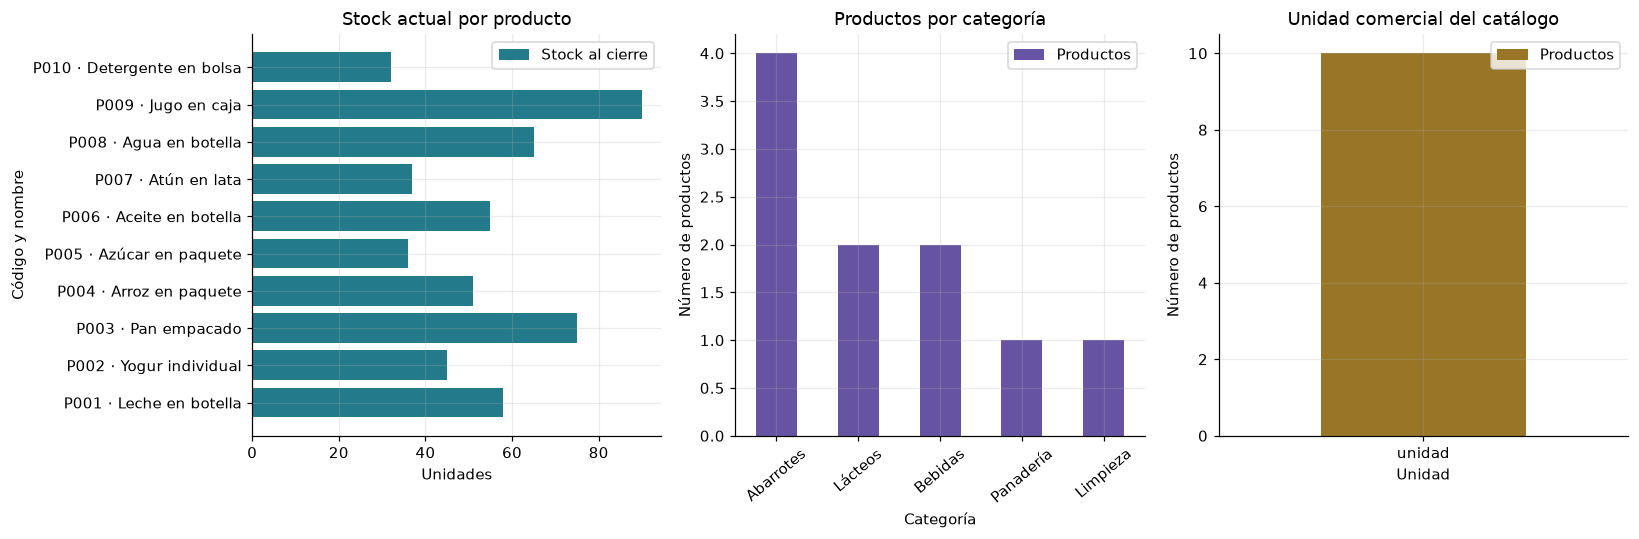

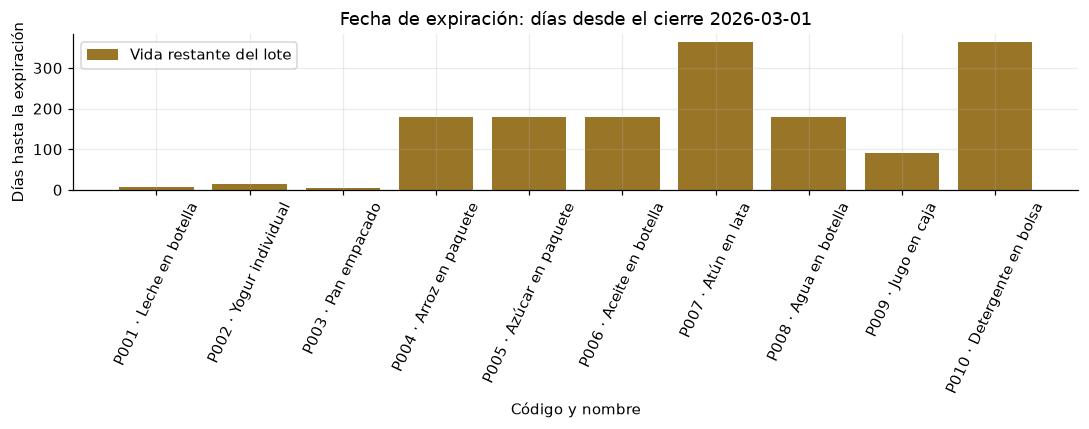

,product_id,nombre,fecha_expiracion
0,P001,Leche en botella,2026-03-08
1,P002,Yogur individual,2026-03-15
2,P003,Pan empacado,2026-03-06
3,P004,Arroz en paquete,2026-08-28
4,P005,Azúcar en paquete,2026-08-28
5,P006,Aceite en botella,2026-08-28
6,P007,Atún en lata,2027-03-01
7,P008,Agua en botella,2026-08-28
8,P009,Jugo en caja,2026-05-30
9,P010,Detergente en bolsa,2027-03-01


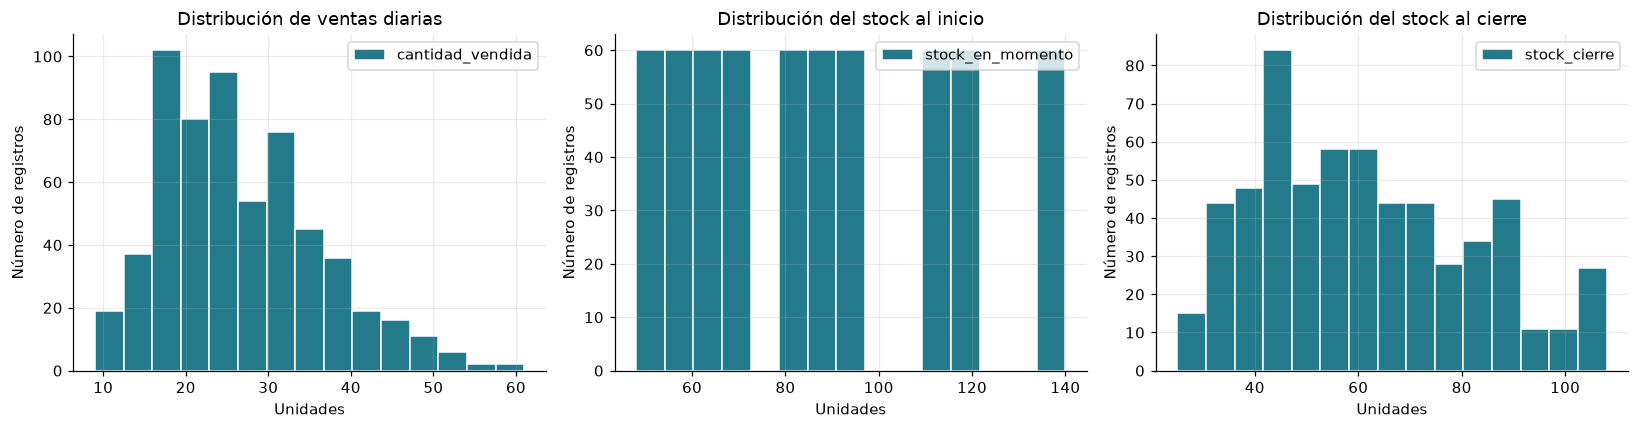

In [6]:
etiquetas = inventario.product_id + " · " + inventario.nombre
fig, ejes = plt.subplots(1, 3, figsize=(15, 5))
ejes[0].barh(etiquetas, inventario.stock_actual, color="#237a8a", label="Stock al cierre")
ejes[0].set(title="Stock actual por producto", xlabel="Unidades", ylabel="Código y nombre")
ejes[0].legend()
inventario.categoria.value_counts().plot.bar(ax=ejes[1], color="#6654a2", label="Productos")
ejes[1].set(title="Productos por categoría", xlabel="Categoría", ylabel="Número de productos")
ejes[1].tick_params(axis="x", rotation=40)
ejes[1].legend()
inventario.unidad.value_counts().plot.bar(ax=ejes[2], color="#997527", label="Productos")
ejes[2].set(title="Unidad comercial del catálogo", xlabel="Unidad", ylabel="Número de productos")
ejes[2].tick_params(axis="x", rotation=0)
ejes[2].legend()
guardar_grafico("01_catalogo_stock")

dias_vencimiento = (inventario.fecha_expiracion - ultima_fecha).dt.days
fig, ax = plt.subplots(figsize=(10, 4))
ax.bar(etiquetas, dias_vencimiento, color="#997527", label="Vida restante del lote")
ax.set(title=f"Fecha de expiración: días desde el cierre {ultima_fecha.date()}",
       xlabel="Código y nombre", ylabel="Días hasta la expiración")
ax.tick_params(axis="x", rotation=65)
ax.legend()
guardar_grafico("02_expiracion")
display(inventario[["product_id", "nombre", "fecha_expiracion"]])

fig, ejes = plt.subplots(1, 3, figsize=(15, 4))
for ax, columna, titulo in zip(ejes, ["cantidad_vendida", "stock_en_momento", "stock_cierre"],
                              ["Distribución de ventas diarias", "Distribución del stock al inicio", "Distribución del stock al cierre"]):
    ax.hist(ventas[columna], bins=15, color="#237a8a", edgecolor="white", label=columna)
    ax.set(title=titulo, xlabel="Unidades", ylabel="Número de registros")
    ax.legend()
guardar_grafico("03_distribuciones")

#### COMPORTAMIENTO TEMPORAL

Se grafica cada producto por separado para observar sus ventas, el stock inicial y el stock al cierre. La línea de stock inicial es constante por la reposición diaria, mientras que la de cierre muestra las variaciones que debe aprender la red.

Los códigos y nombres identifican las series; categoría y unidad son atributos fijos del catálogo. La fecha de venta ordena las observaciones. La fecha de expiración pertenece al inventario del último día y se representa mediante los días de vida restantes, porque no se dispone de su evolución histórica.

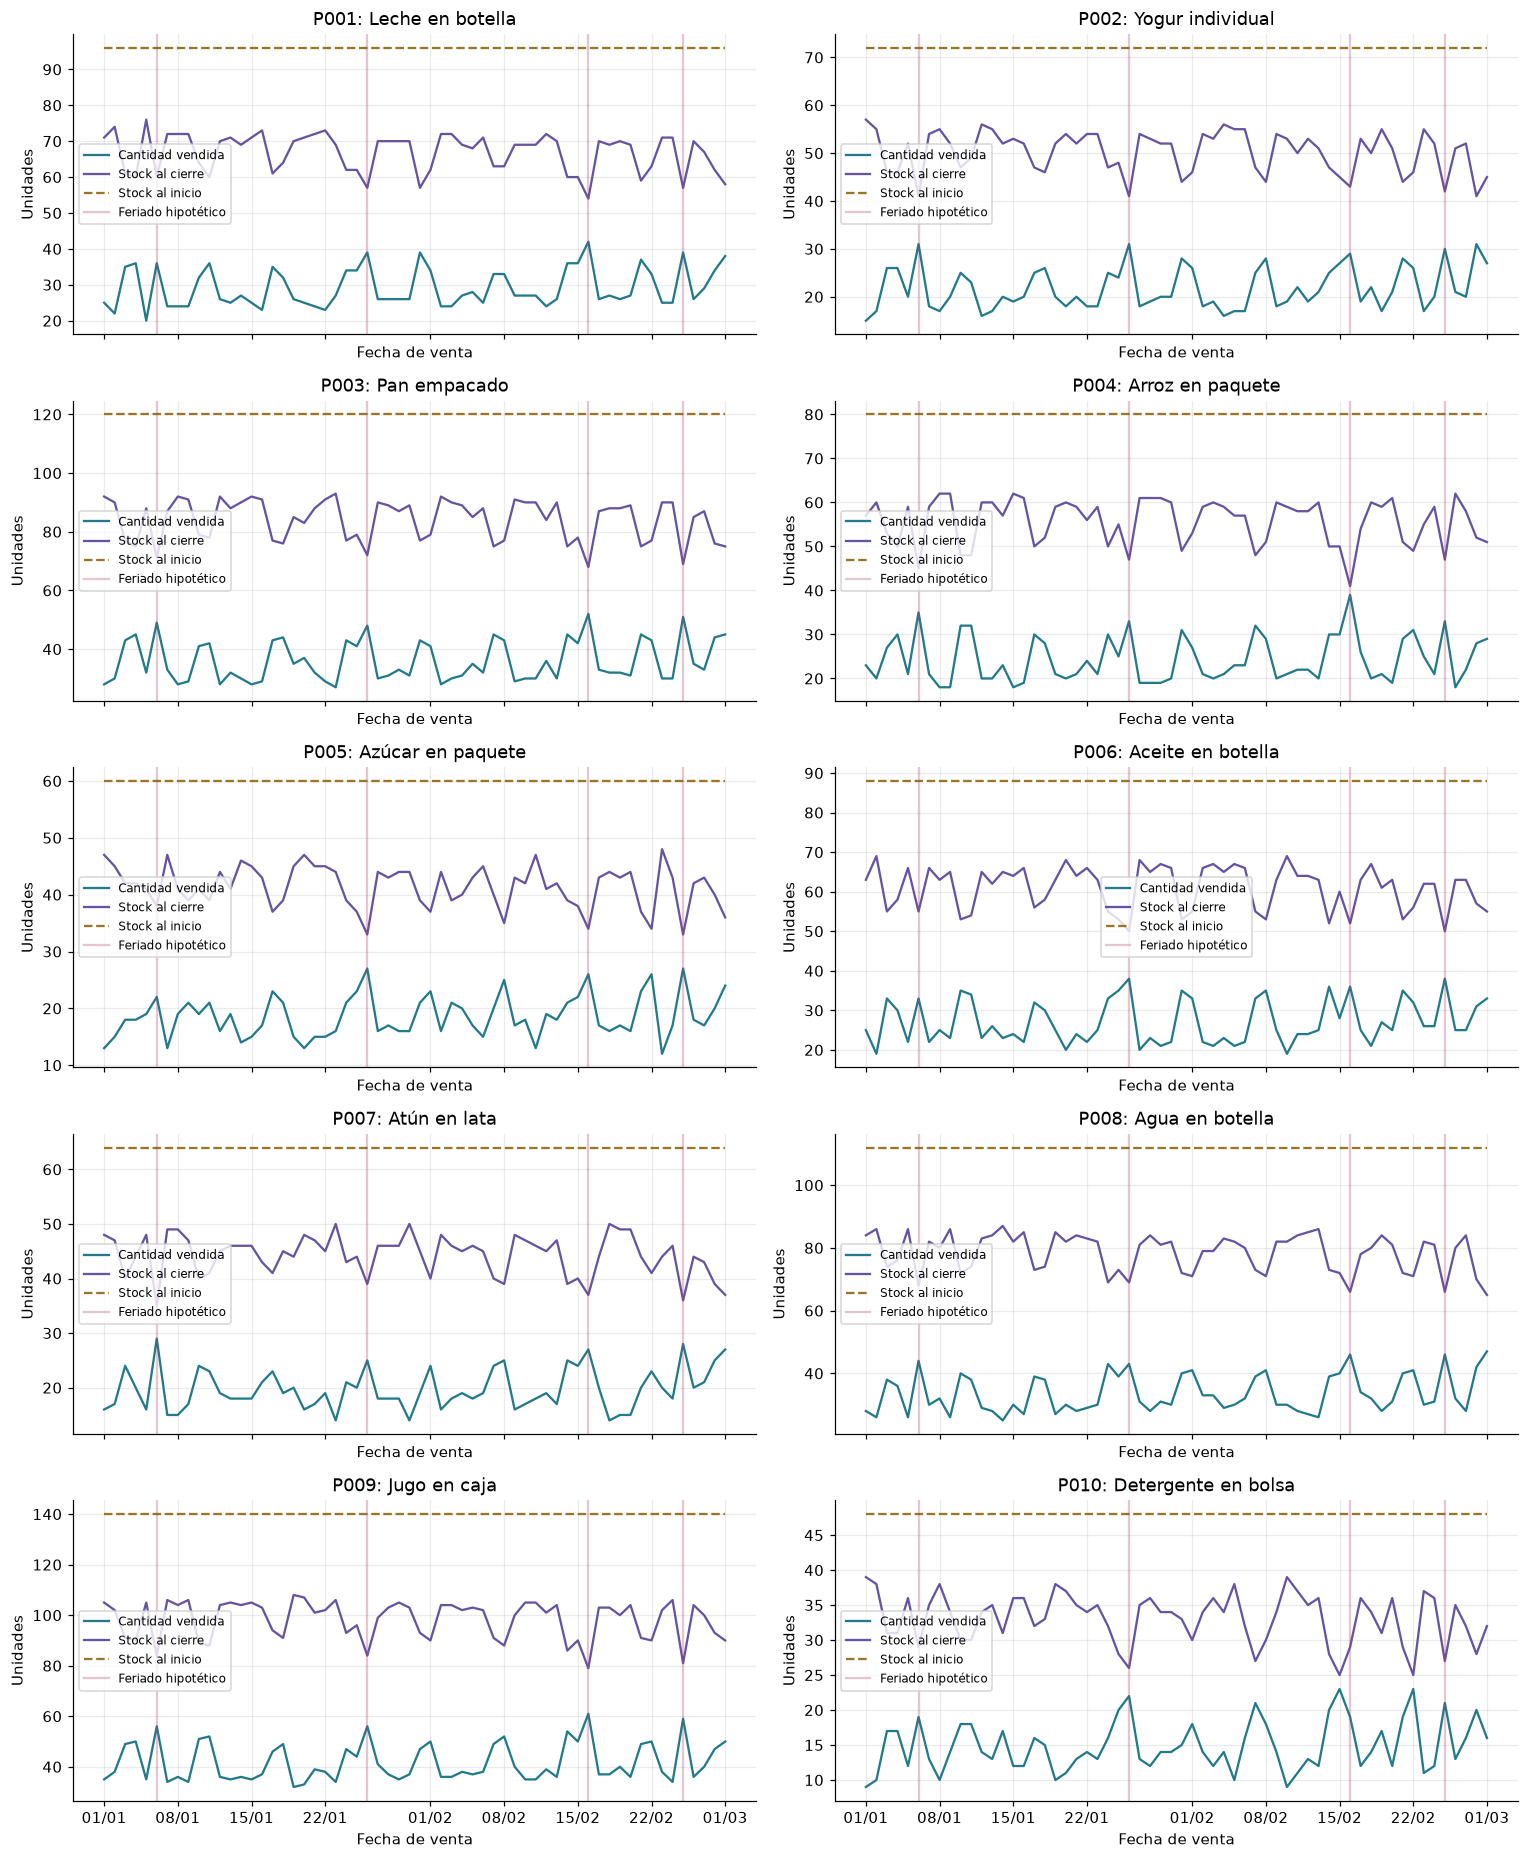

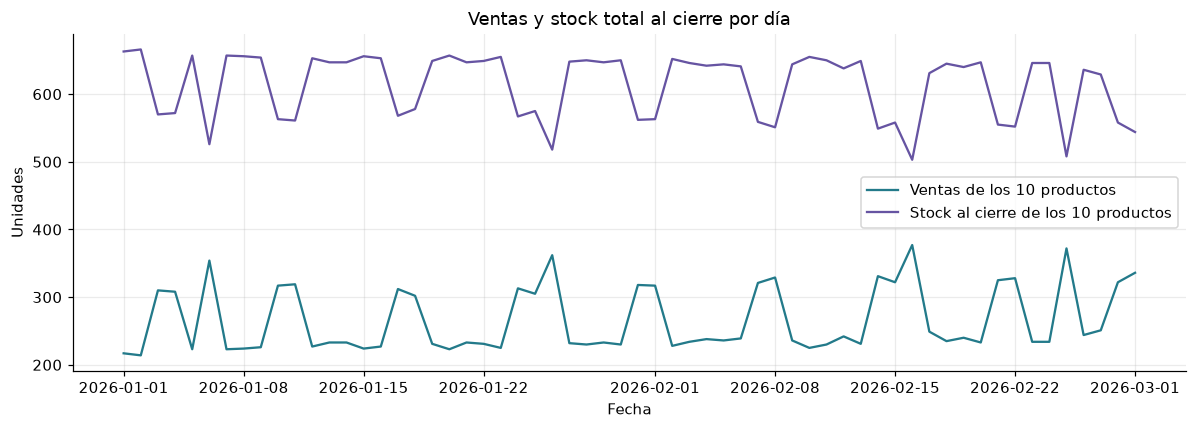

Los picos y cambios semanales de estos gráficos proceden de las reglas de generación. No prueban estacionalidad real del comercio. Con solo 60 días tampoco se puede estudiar un ciclo anual.

In [7]:
fig, ejes = plt.subplots(5, 2, figsize=(14, 17), sharex=True)
for ax, (codigo, grupo) in zip(ejes.flat, ventas.groupby("product_id")):
    ax.plot(grupo.fecha_venta, grupo.cantidad_vendida, label="Cantidad vendida", color="#237a8a")
    ax.plot(grupo.fecha_venta, grupo.stock_cierre, label="Stock al cierre", color="#6654a2")
    ax.plot(grupo.fecha_venta, grupo.stock_en_momento, label="Stock al inicio",
            color="#997527", linestyle="--")
    for posicion, feriado in enumerate(FERIADOS):
        ax.axvline(feriado, color="#aa4263", alpha=0.30,
                   label="Feriado hipotético" if posicion == 0 else None)
    ax.set(title=f"{codigo}: {grupo.nombre.iloc[0]}", xlabel="Fecha de venta", ylabel="Unidades")
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%d/%m"))
    ax.legend(fontsize=8)
guardar_grafico("04_evolucion_por_producto")

fig, ax = plt.subplots(figsize=(11, 4))
total_diario = ventas.groupby("fecha_venta")[["cantidad_vendida", "stock_cierre"]].sum()
ax.plot(total_diario.index, total_diario.cantidad_vendida, label="Ventas de los 10 productos", color="#237a8a")
ax.plot(total_diario.index, total_diario.stock_cierre, label="Stock al cierre de los 10 productos", color="#6654a2")
ax.set(title="Ventas y stock total al cierre por día", xlabel="Fecha", ylabel="Unidades")
ax.legend()
guardar_grafico("05_ventas_totales")

display(Markdown("Los picos y cambios semanales de estos gráficos proceden de las reglas de generación. "
                 "No prueban estacionalidad real del comercio. Con solo 60 días tampoco se puede estudiar un ciclo anual."))

#### INGENIERÍA DE CARACTERÍSTICAS

La salida **y es el stock al cierre del día objetivo**. La entrada básica contiene el stock de cierre de los días anteriores y columnas 0/1 que identifican el producto. Los códigos se tratan como categorías, evitando interpretar P010 como una cantidad mayor que P001.

La versión ampliada incluye día de la semana, mes, día del mes, fin de semana y feriado del día siguiente a cada observación. Estos datos se conocen antes de predecir. Se crean dos variables combinadas: stock observado × fin de semana siguiente y stock observado × feriado siguiente.

El calendario es relevante porque modifica las ventas simuladas y, por tanto, las existencias al cierre. Todas las entradas proceden del historial anterior o del calendario conocido. **Las ventas del día que se pronostica no se usan como entrada.** Tampoco se repite el stock actual del último cierre en fechas históricas.

,product_id,fecha_venta,stock_cierre,producto_P001,producto_P002,producto_P003,producto_P004,producto_P005,producto_P006,producto_P007,producto_P008,producto_P009,producto_P010,dia_semana_siguiente,mes_siguiente,dia_mes_siguiente,fin_semana_siguiente,feriado_siguiente,stock_x_fin_semana,stock_x_feriado
0,P001,2026-01-01,71.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,4.0,1.0,2.0,0.0,0.0,0.0,0.0
1,P001,2026-01-02,74.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,5.0,1.0,3.0,1.0,0.0,74.0,0.0
2,P001,2026-01-03,61.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,6.0,1.0,4.0,1.0,0.0,61.0,0.0
3,P001,2026-01-04,60.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,5.0,0.0,0.0,0.0,0.0
4,P001,2026-01-05,76.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,6.0,0.0,1.0,0.0,76.0
5,P001,2026-01-06,60.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,2.0,1.0,7.0,0.0,0.0,0.0,0.0
6,P001,2026-01-07,72.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,3.0,1.0,8.0,0.0,0.0,0.0,0.0
7,P001,2026-01-08,72.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,4.0,1.0,9.0,0.0,0.0,0.0,0.0


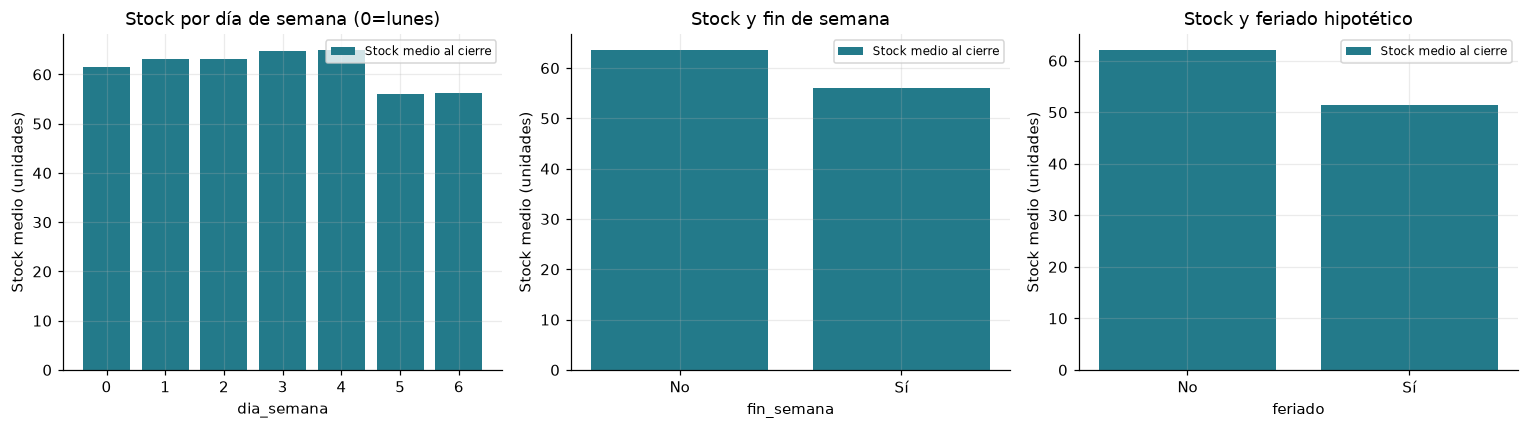

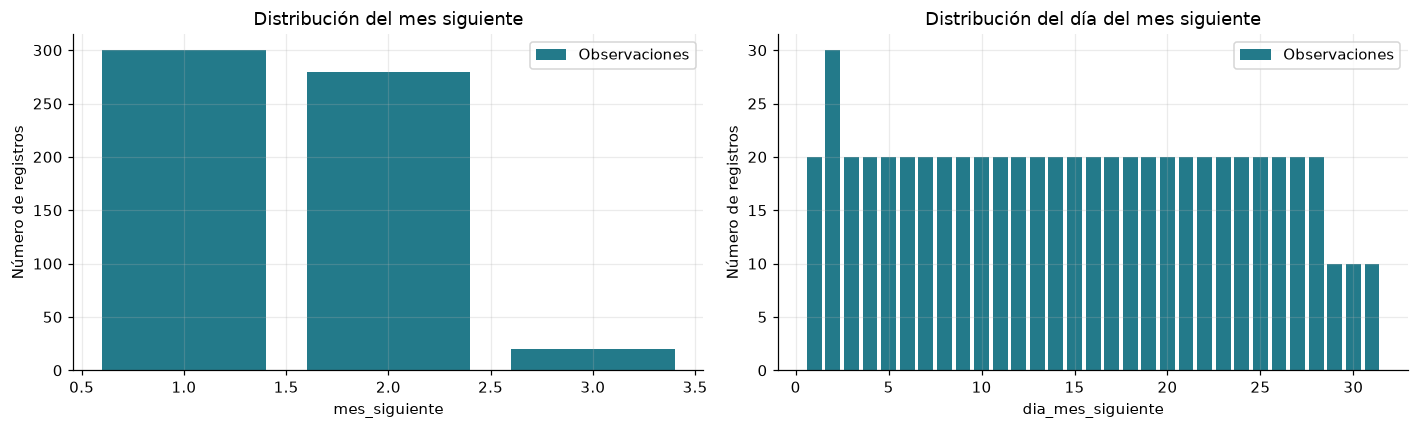

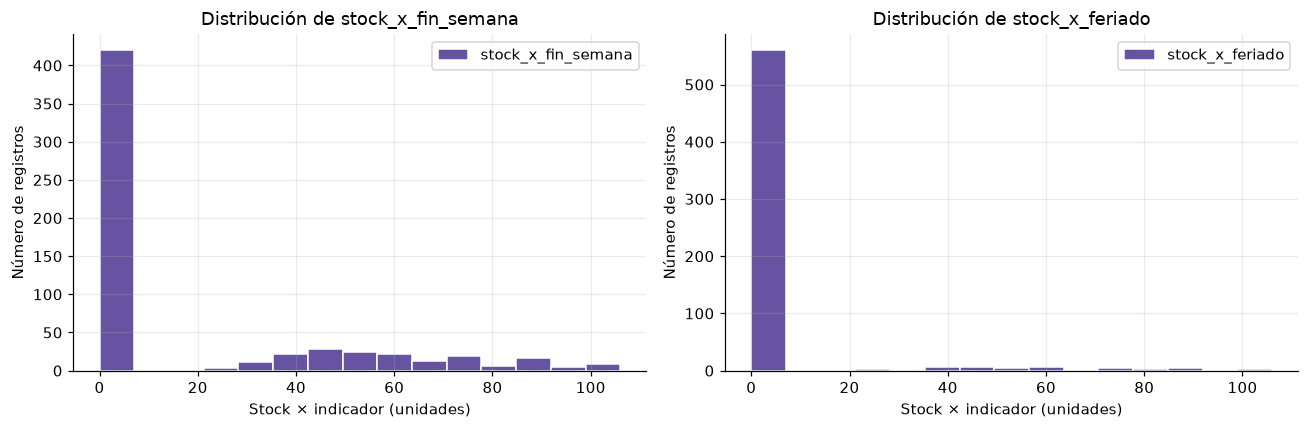

In [8]:
CODIGOS = inventario.product_id.tolist()

def crear_variables(historial, usar_ingenieria=True):
    datos = historial.reset_index(drop=True)
    variables = pd.DataFrame({"stock_cierre": datos.stock_cierre.astype(float)})
    for codigo in CODIGOS:
        variables[f"producto_{codigo}"] = (datos.product_id == codigo).astype(float)
    if usar_ingenieria:
        siguiente = pd.to_datetime(datos.fecha_venta) + pd.Timedelta(days=1)
        variables["dia_semana_siguiente"] = siguiente.dt.dayofweek
        variables["mes_siguiente"] = siguiente.dt.month
        variables["dia_mes_siguiente"] = siguiente.dt.day
        variables["fin_semana_siguiente"] = (siguiente.dt.dayofweek >= 5).astype(int)
        variables["feriado_siguiente"] = siguiente.isin(FERIADOS).astype(int)
        variables["stock_x_fin_semana"] = variables.stock_cierre * variables.fin_semana_siguiente
        variables["stock_x_feriado"] = variables.stock_cierre * variables.feriado_siguiente
    return variables.astype("float32")

variables_ampliadas = crear_variables(ventas)
display(pd.concat([ventas[["product_id", "fecha_venta"]], variables_ampliadas], axis=1).head(8))
analisis_calendario = ventas.assign(
    dia_semana=ventas.fecha_venta.dt.dayofweek,
    fin_semana=np.where(ventas.fecha_venta.dt.dayofweek.ge(5), "Sí", "No"),
    feriado=np.where(ventas.fecha_venta.isin(FERIADOS), "Sí", "No"))
fig, ejes = plt.subplots(1, 3, figsize=(14, 4))
for ax, columna, titulo in zip(ejes, ["dia_semana", "fin_semana", "feriado"],
                              ["Stock por día de semana (0=lunes)", "Stock y fin de semana", "Stock y feriado hipotético"]):
    medias = analisis_calendario.groupby(columna).stock_cierre.mean()
    ax.bar(medias.index.astype(str), medias.values, color="#237a8a", label="Stock medio al cierre")
    ax.set(title=titulo, xlabel=columna, ylabel="Stock medio (unidades)")
    ax.legend(fontsize=8)
guardar_grafico("06_calendario")

fig, ejes = plt.subplots(1, 2, figsize=(13, 4))
for ax, columna, titulo in zip(ejes, ["mes_siguiente", "dia_mes_siguiente"],
                              ["Distribución del mes siguiente", "Distribución del día del mes siguiente"]):
    frecuencias = variables_ampliadas[columna].value_counts().sort_index()
    ax.bar(frecuencias.index.astype(int), frecuencias.values, color="#237a8a", label="Observaciones")
    ax.set(title=titulo, xlabel=columna, ylabel="Número de registros")
    ax.legend()
guardar_grafico("10_variables_temporales")

fig, ejes = plt.subplots(1, 2, figsize=(12, 4))
for ax, columna in zip(ejes, ["stock_x_fin_semana", "stock_x_feriado"]):
    ax.hist(variables_ampliadas[columna], bins=15, color="#6654a2", edgecolor="white", label=columna)
    ax.set(title=f"Distribución de {columna}", xlabel="Stock × indicador (unidades)", ylabel="Número de registros")
    ax.legend()
guardar_grafico("11_variables_combinadas")

#### PARTICIÓN TEMPORAL Y SECUENCIAS SUPERVISADAS

Los primeros **42 días se destinan al entrenamiento (70 %)**, los siguientes **9 a validación (15 %)** y los últimos **9 a prueba (15 %)**. Esta separación respeta el orden temporal: el modelo aprende del pasado y se evalúa en fechas posteriores. La validación permite elegir la configuración y la prueba mide su desempeño final.

La función `series_to_supervised` convierte el historial en un problema de regresión supervisada. Las existencias anteriores forman la entrada X y el stock al cierre del día objetivo forma la salida y. Las secuencias se construyen por separado para cada producto; por ejemplo, una ventana de 3 días utiliza únicamente los tres días anteriores de ese mismo producto.

Se aplica `MinMaxScaler` a las entradas y a la salida con escaladores separados. Ambos se ajustan solamente con el tramo de entrenamiento. Esta separación permite recuperar las predicciones en unidades de stock sin usar los datos de validación o prueba durante la normalización.

In [9]:
indice_entrenamiento = int(len(fechas_disponibles) * 0.70)
indice_validacion = int(len(fechas_disponibles) * 0.85)
inicio_validacion = fechas_disponibles[indice_entrenamiento]
inicio_prueba = fechas_disponibles[indice_validacion]
display(pd.DataFrame([
    ["Entrenamiento", fechas_disponibles[0].date(), (inicio_validacion - pd.Timedelta(days=1)).date()],
    ["Validación", inicio_validacion.date(), (inicio_prueba - pd.Timedelta(days=1)).date()],
    ["Prueba", inicio_prueba.date(), ultima_fecha.date()],
], columns=["particion", "desde", "hasta"]))

def series_to_supervised(data, n_in=1):
    """Combina observaciones anteriores; la última columna es el stock objetivo."""
    df = pd.DataFrame(data)
    bloques = [df.shift(paso) for paso in range(n_in, 0, -1)]
    bloques.append(df.iloc[:, [0]])
    return pd.concat(bloques, axis=1).dropna()

# Ejemplo pequeño que permite comprobar la alineación antes de entrenar.
ejemplo = series_to_supervised(np.array([[10], [20], [30], [40]]), n_in=2)
assert np.array_equal(ejemplo.to_numpy(), [[10, 20, 30], [20, 30, 40]])
display(ejemplo.set_axis(["stock(t-2)", "stock(t-1)", "stock(t)"], axis=1))

def preparar_secuencias(n_dias, usar_ingenieria, usar_todo=False):
    entradas = crear_variables(ventas, usar_ingenieria)
    mascara_ajuste = np.ones(len(ventas), dtype=bool) if usar_todo else (ventas.fecha_venta < inicio_validacion)
    scaler_X = MinMaxScaler().fit(entradas.loc[mascara_ajuste])
    scaler_y = MinMaxScaler().fit(ventas.loc[mascara_ajuste, ["stock_cierre"]])
    X, y, registros = [], [], []
    for codigo, grupo in ventas.groupby("product_id", sort=True):
        grupo = grupo.reset_index(drop=True)
        valores = scaler_X.transform(crear_variables(grupo, usar_ingenieria))
        supervisado = series_to_supervised(valores, n_in=n_dias)
        matriz = supervisado.to_numpy(dtype="float32")
        X.append(matriz[:, :-1].reshape(-1, n_dias, entradas.shape[1]))
        y.append(scaler_y.transform(grupo.loc[n_dias:, ["stock_cierre"]]).astype("float32"))
        registros.append(grupo.loc[n_dias:, ["product_id", "fecha_venta", "stock_cierre"]])
        # Cada ventana termina justo un día antes de su objetivo y no cambia de producto.
        assert (grupo.fecha_venta.diff().dropna() == pd.Timedelta(days=1)).all()
    X, y = np.concatenate(X), np.concatenate(y)
    meta = pd.concat(registros, ignore_index=True)
    mascaras = {
        "train": (meta.fecha_venta < inicio_validacion).to_numpy(),
        "val": ((meta.fecha_venta >= inicio_validacion) & (meta.fecha_venta < inicio_prueba)).to_numpy(),
        "test": (meta.fecha_venta >= inicio_prueba).to_numpy(),
    }
    assert meta.loc[mascaras["train"], "fecha_venta"].max() < meta.loc[mascaras["val"], "fecha_venta"].min()
    assert meta.loc[mascaras["val"], "fecha_venta"].max() < meta.loc[mascaras["test"], "fecha_venta"].min()
    return {"X": X, "y": y, "meta": meta, "mascaras": mascaras,
            "scaler_X": scaler_X, "scaler_y": scaler_y,
            "columnas": entradas.columns.tolist()}

datos_ejemplo = preparar_secuencias(3, True)
for particion, mascara in datos_ejemplo["mascaras"].items():
    print(particion, "X:", datos_ejemplo["X"][mascara].shape,
          "y:", datos_ejemplo["y"][mascara].shape)
print("X tiene la forma [muestras, días anteriores, variables].")

# Se comprueba el objetivo en unidades originales y la alineación de la primera ventana.
mascara = datos_ejemplo["mascaras"]["train"]
stock_observado = datos_ejemplo["meta"].loc[mascara, "stock_cierre"].to_numpy()
assert np.allclose(datos_ejemplo["scaler_y"].inverse_transform(datos_ejemplo["y"][mascara]).ravel(), stock_observado)
historial_producto = ventas.loc[ventas.product_id == CODIGOS[0]].reset_index(drop=True)
ventana_recuperada = datos_ejemplo["scaler_X"].inverse_transform(datos_ejemplo["X"][0])
assert np.allclose(ventana_recuperada[:, 0], historial_producto.stock_cierre.iloc[:3])
assert datos_ejemplo["meta"].stock_cierre.iloc[0] == historial_producto.stock_cierre.iloc[3]


,particion,desde,hasta
0,Entrenamiento,2026-01-01,2026-02-11
1,Validación,2026-02-12,2026-02-20
2,Prueba,2026-02-21,2026-03-01


,stock(t-2),stock(t-1),stock(t)
2,10.0,20.0,30
3,20.0,30.0,40


train X: (390, 3, 18) y: (390, 1)
val X: (90, 3, 18) y: (90, 1)
test X: (90, 3, 18) y: (90, 1)
X tiene la forma [muestras, días anteriores, variables].


<div id="RNN" style="color:#37475a; border-bottom: 7px solid orange; width: 100%; margin-bottom: 15px; padding-bottom: 2px"><h2>Desarrollo de la RNN</h2> </div>

#### RED NEURONAL LSTM Y ENTRENAMIENTO

Una LSTM procesa observaciones en su orden temporal y mantiene información de sus pasos anteriores. Recibe el historial de existencias y las características de los días previos para estimar el stock al cierre del día siguiente.

Se utiliza una capa **LSTM de 50 neuronas** y una capa **Dense(1)** como salida de regresión. El entrenamiento emplea Adam, pérdida MAE, lotes de 72 muestras y un máximo de 50 épocas. La parada temprana recupera los pesos de la mejor época cuando el MSE de validación deja de mejorar durante 10 épocas.

El desempeño se evalúa con MSE y RMSE después de desnormalizar:

$$MSE = \frac{1}{n}\sum_{i=1}^{n}(y_i-\hat{y}_i)^2, \qquad RMSE = \sqrt{MSE}$$

Aquí, $y_i$ es el stock observado, $\hat{y}_i$ es el stock predicho y $n$ es el número de observaciones. El MSE se expresa en unidades al cuadrado y da más peso a errores grandes. El RMSE se expresa en unidades de stock.

Primero se comparan dos modelos con una ventana de 1 día, sin y con ingeniería de características. El **ajuste de hiperparámetros (fine-tuning)** prueba también ventanas de 3 y 7 días. Se mantiene la arquitectura y las condiciones de entrenamiento para estudiar el efecto de la información temporal.

In [10]:
def construir_modelo(n_dias, n_variables):
    tf.keras.utils.set_random_seed(SEMILLA)
    model = Sequential([Input(shape=(n_dias, n_variables)), LSTM(50), Dense(1)])
    model.compile(loss="mae", optimizer="adam", metrics=["mse"])
    return model

def datos_por_lotes(X, y):
    dataset = tf.data.Dataset.from_tensor_slices((X, y)).batch(72)
    opciones = tf.data.Options()
    opciones.threading.private_threadpool_size = 1
    opciones.threading.max_intra_op_parallelism = 1
    return dataset.with_options(opciones)

def predecir_unidades(modelo, X, scaler_y, codigos):
    normalizado = modelo(X, training=False).numpy()
    stock = scaler_y.inverse_transform(normalizado).ravel()
    limites = np.array([NIVELES_REPOSICION[codigo] for codigo in codigos])
    # Los mismos límites físicos se aplican en evaluación y en las consultas.
    return np.clip(stock, 0, limites)

configuraciones = [
    {"nombre": "Base: 1 día sin ingeniería", "n_dias": 1, "ingenieria": False},
    {"nombre": "FE: 1 día", "n_dias": 1, "ingenieria": True},
    {"nombre": "FE: 3 días", "n_dias": 3, "ingenieria": True},
    {"nombre": "FE: 7 días", "n_dias": 7, "ingenieria": True},
]
experimentos = []
for configuracion in configuraciones:
    datos = preparar_secuencias(configuracion["n_dias"], configuracion["ingenieria"])
    tr, va = datos["mascaras"]["train"], datos["mascaras"]["val"]
    model = construir_modelo(configuracion["n_dias"], datos["X"].shape[2])
    parada = EarlyStopping(monitor="val_mse", patience=10, restore_best_weights=True, mode="min")
    history = model.fit(datos_por_lotes(datos["X"][tr], datos["y"][tr]),
                        validation_data=datos_por_lotes(datos["X"][va], datos["y"][va]),
                        epochs=50, callbacks=[parada], verbose=0, shuffle=False)
    pred_val = predecir_unidades(model, datos["X"][va], datos["scaler_y"], datos["meta"].loc[va, "product_id"])
    real_val = datos["meta"].loc[va, "stock_cierre"].to_numpy()
    mse_val = mean_squared_error(real_val, pred_val)
    mejor_epoca = int(np.argmin(history.history["val_mse"]) + 1)
    experimentos.append({**configuracion, "model": model, "datos": datos,
                         "history": history, "MSE_val": mse_val,
                         "mejor_epoca": mejor_epoca,
                         "epocas_ejecutadas": len(history.history["loss"])})
    print(f"{configuracion['nombre']}: MSE validación={mse_val:.4f}; mejor época={mejor_epoca}")

seleccionado = min(experimentos, key=lambda resultado: resultado["MSE_val"])
print("Configuración elegida solo por validación:", seleccionado["nombre"])
experimentos[0]["model"].summary()

Base: 1 día sin ingeniería: MSE validación=34.5267; mejor época=32


FE: 1 día: MSE validación=6.6602; mejor época=50


FE: 3 días: MSE validación=5.6888; mejor época=45


FE: 7 días: MSE validación=5.6384; mejor época=50
Configuración elegida solo por validación: FE: 7 días


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 50)             │        12,400 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │            51 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 37,355 (145.92 KB)

 Trainable params: 12,451 (48.64 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 24,904 (97.29 KB)

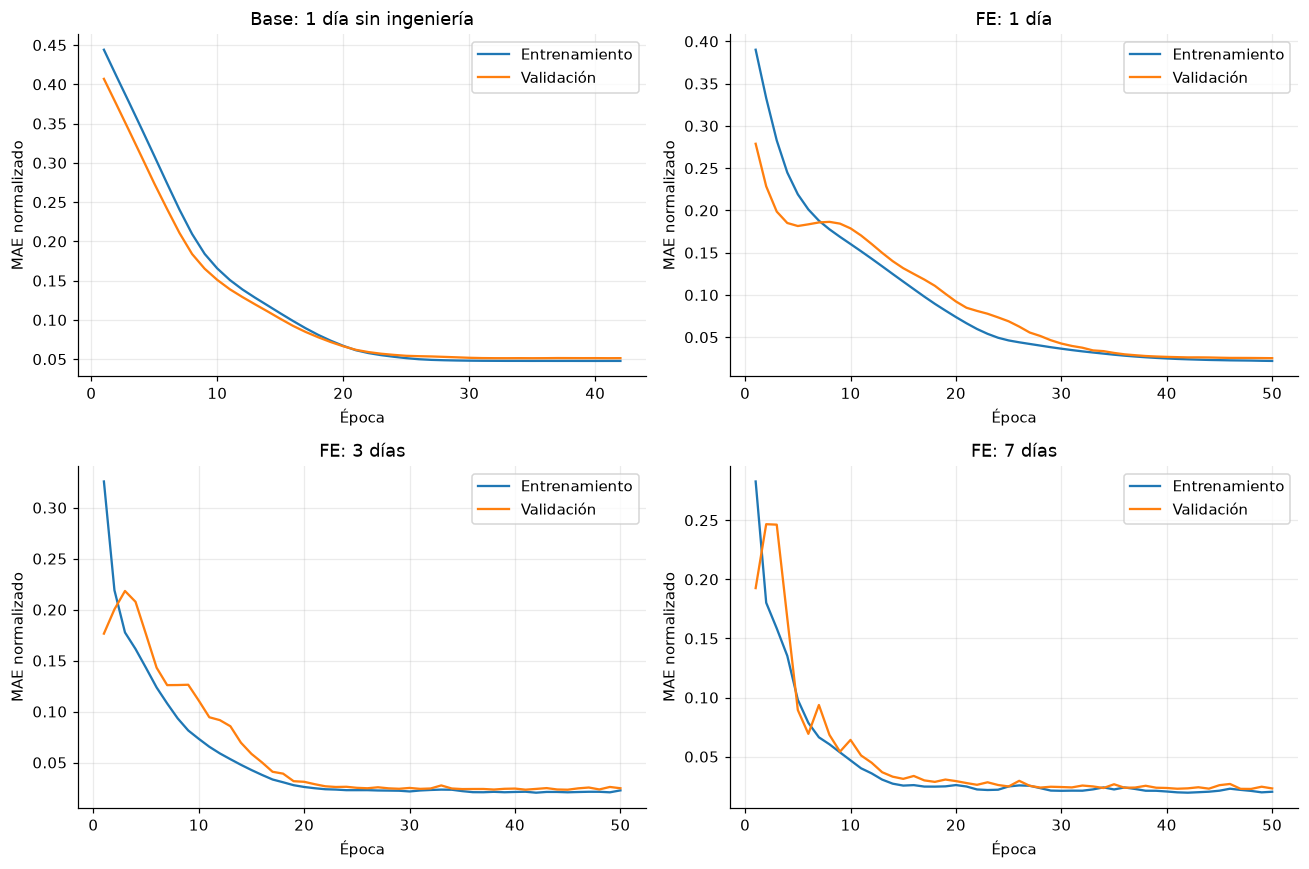

Las curvas permiten comparar aprendizaje y validación. Una pérdida de entrenamiento cada vez menor acompañada de una validación que empeora sugiere sobreajuste. La parada temprana evita conservar la última época si una anterior generaliza mejor.

In [11]:
fig, ejes = plt.subplots(2, 2, figsize=(12, 8))
for ax, experimento in zip(ejes.flat, experimentos):
    history = experimento["history"].history
    epocas = range(1, len(history["loss"]) + 1)
    ax.plot(epocas, history["loss"], label="Entrenamiento")
    ax.plot(epocas, history["val_loss"], label="Validación")
    ax.set(title=experimento["nombre"], xlabel="Época", ylabel="MAE normalizado")
    ax.legend()
guardar_grafico("07_curvas_entrenamiento")
display(Markdown("Las curvas permiten comparar aprendizaje y validación. Una pérdida de entrenamiento "
                 "cada vez menor acompañada de una validación que empeora sugiere sobreajuste. "
                 "La parada temprana evita conservar la última época si una anterior generaliza mejor."))

#### EVALUACIÓN EN PRUEBA Y COMPARACIÓN

Después de seleccionar la configuración con validación, los modelos se evalúan en las mismas fechas de prueba. También se calcula una predicción de persistencia, que supone que el stock de mañana será igual al de hoy. Este modelo sencillo permite comprobar si la red neuronal aporta una mejora.

La evaluación pronostica **un día hacia adelante con origen móvil**. Para cada fecha se utilizan las existencias observadas hasta el día anterior, incluidas las que ya se conocen dentro del periodo de prueba. Este procedimiento representa una consulta diaria después del cierre de ventas. En cambio, cuando las funciones reciben una fecha a varios días, deben utilizar predicciones intermedias porque todavía no existen stocks observados para esas fechas.

,modelo,dias_ventana,MSE_validacion,MSE_prueba,RMSE_prueba,mejor_epoca,epocas_ejecutadas
0,Base: 1 día sin ingeniería,1,34.5267,53.6126,7.3221,32,42
1,FE: 1 día,1,6.6602,7.2104,2.6852,50,50
2,FE: 3 días,3,5.6888,5.9357,2.4363,45,50
3,FE: 7 días,7,5.6384,5.9867,2.4468,50,50


Persistencia: MSE=76.2111; RMSE=8.7299 unidades


**Comparación antes/después:** con la misma ventana de 1 día, el MSE pasó de **53.6126** a **7.2104**. La ingeniería redujo el error en **86.55 %**. Esto describe el resultado observado y no garantiza mejoras en otros datos. **Modelo elegido:** FE: 7 días, con MSE de prueba **5.9867** y RMSE **2.4468 unidades**. El RMSE resume el tamaño del error, dando más peso a errores grandes; no es un porcentaje. La persistencia obtuvo RMSE **8.7299 unidades**.

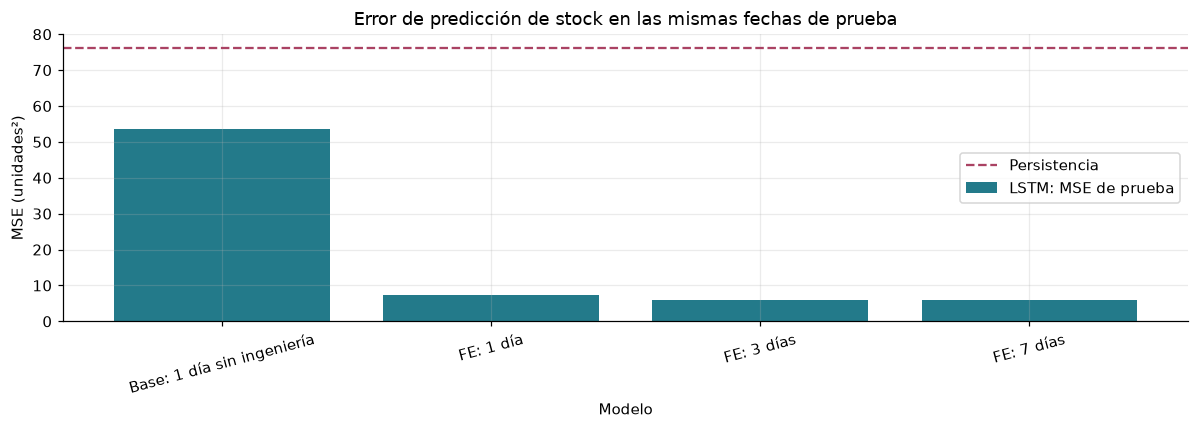

In [12]:
filas_metricas, predicciones_modelos = [], {}
for experimento in experimentos:
    datos = experimento["datos"]
    te = datos["mascaras"]["test"]
    meta = datos["meta"].loc[te].reset_index(drop=True)
    prediccion = predecir_unidades(experimento["model"], datos["X"][te], datos["scaler_y"], meta.product_id)
    mse = mean_squared_error(meta.stock_cierre, prediccion)
    filas_metricas.append({"modelo": experimento["nombre"], "dias_ventana": experimento["n_dias"],
                           "MSE_validacion": experimento["MSE_val"], "MSE_prueba": mse,
                           "RMSE_prueba": np.sqrt(mse), "mejor_epoca": experimento["mejor_epoca"],
                           "epocas_ejecutadas": experimento["epocas_ejecutadas"]})
    predicciones_modelos[experimento["nombre"]] = meta.assign(prediccion=prediccion)

persistencia = ventas.assign(prediccion=ventas.groupby("product_id").stock_cierre.shift(1))
persistencia = persistencia.loc[persistencia.fecha_venta >= inicio_prueba]
mse_persistencia = mean_squared_error(persistencia.stock_cierre, persistencia.prediccion)
metricas = pd.DataFrame(filas_metricas)
display(metricas.round(4))
print(f"Persistencia: MSE={mse_persistencia:.4f}; RMSE={np.sqrt(mse_persistencia):.4f} unidades")
metricas.to_csv(TABLAS / "metricas_modelos.csv", index=False)
predicciones_prueba = predicciones_modelos[seleccionado["nombre"]]
predicciones_prueba.to_csv(TABLAS / "predicciones_prueba.csv", index=False)
assert len(predicciones_prueba) == len(persistencia)
for tabla in predicciones_modelos.values():
    assert tabla[["product_id", "fecha_venta"]].equals(
        predicciones_prueba[["product_id", "fecha_venta"]])

mse_base, mse_fe = metricas.MSE_prueba.iloc[:2]
cambio_fe = 100 * (mse_base - mse_fe) / mse_base
fila_elegida = metricas.loc[metricas.modelo == seleccionado["nombre"]].iloc[0]
verbo = "redujo" if cambio_fe >= 0 else "aumentó"
display(Markdown(
    f"**Comparación antes/después:** con la misma ventana de 1 día, el MSE pasó de "
    f"**{mse_base:.4f}** a **{mse_fe:.4f}**. La ingeniería {verbo} el error en "
    f"**{abs(cambio_fe):.2f} %**. Esto describe el resultado observado y no garantiza mejoras en otros datos. "
    f"**Modelo elegido:** {seleccionado['nombre']}, con MSE de prueba "
    f"**{fila_elegida.MSE_prueba:.4f}** y RMSE **{fila_elegida.RMSE_prueba:.4f} unidades**. "
    f"El RMSE resume el tamaño del error, dando más peso a errores grandes; no es un porcentaje. "
    f"La persistencia obtuvo RMSE **{np.sqrt(mse_persistencia):.4f} unidades**."))

fig, ax = plt.subplots(figsize=(11, 4))
ax.bar(metricas.modelo, metricas.MSE_prueba, color="#237a8a", label="LSTM: MSE de prueba")
ax.axhline(mse_persistencia, color="#aa4263", linestyle="--", label="Persistencia")
ax.set(title="Error de predicción de stock en las mismas fechas de prueba", xlabel="Modelo", ylabel="MSE (unidades²)")
ax.tick_params(axis="x", rotation=15)
ax.legend()
guardar_grafico("08_comparacion_mse")

#### INTERPRETACIÓN DE LA COMPARACIÓN Y DEL AJUSTE

La comparación entre los modelos con ventana de 1 día muestra el efecto de agregar características de calendario y variables combinadas. Un MSE menor indica que las predicciones de stock se acercan más a las existencias observadas.

La ventana final se elige por el MSE de validación. Los errores de prueba se presentan después de esa selección, incluso si otra configuración logra un error de prueba menor. Así se evita usar las mismas observaciones para decidir y evaluar el modelo. Todos los resultados de esta sección corresponden al stock de cierre.

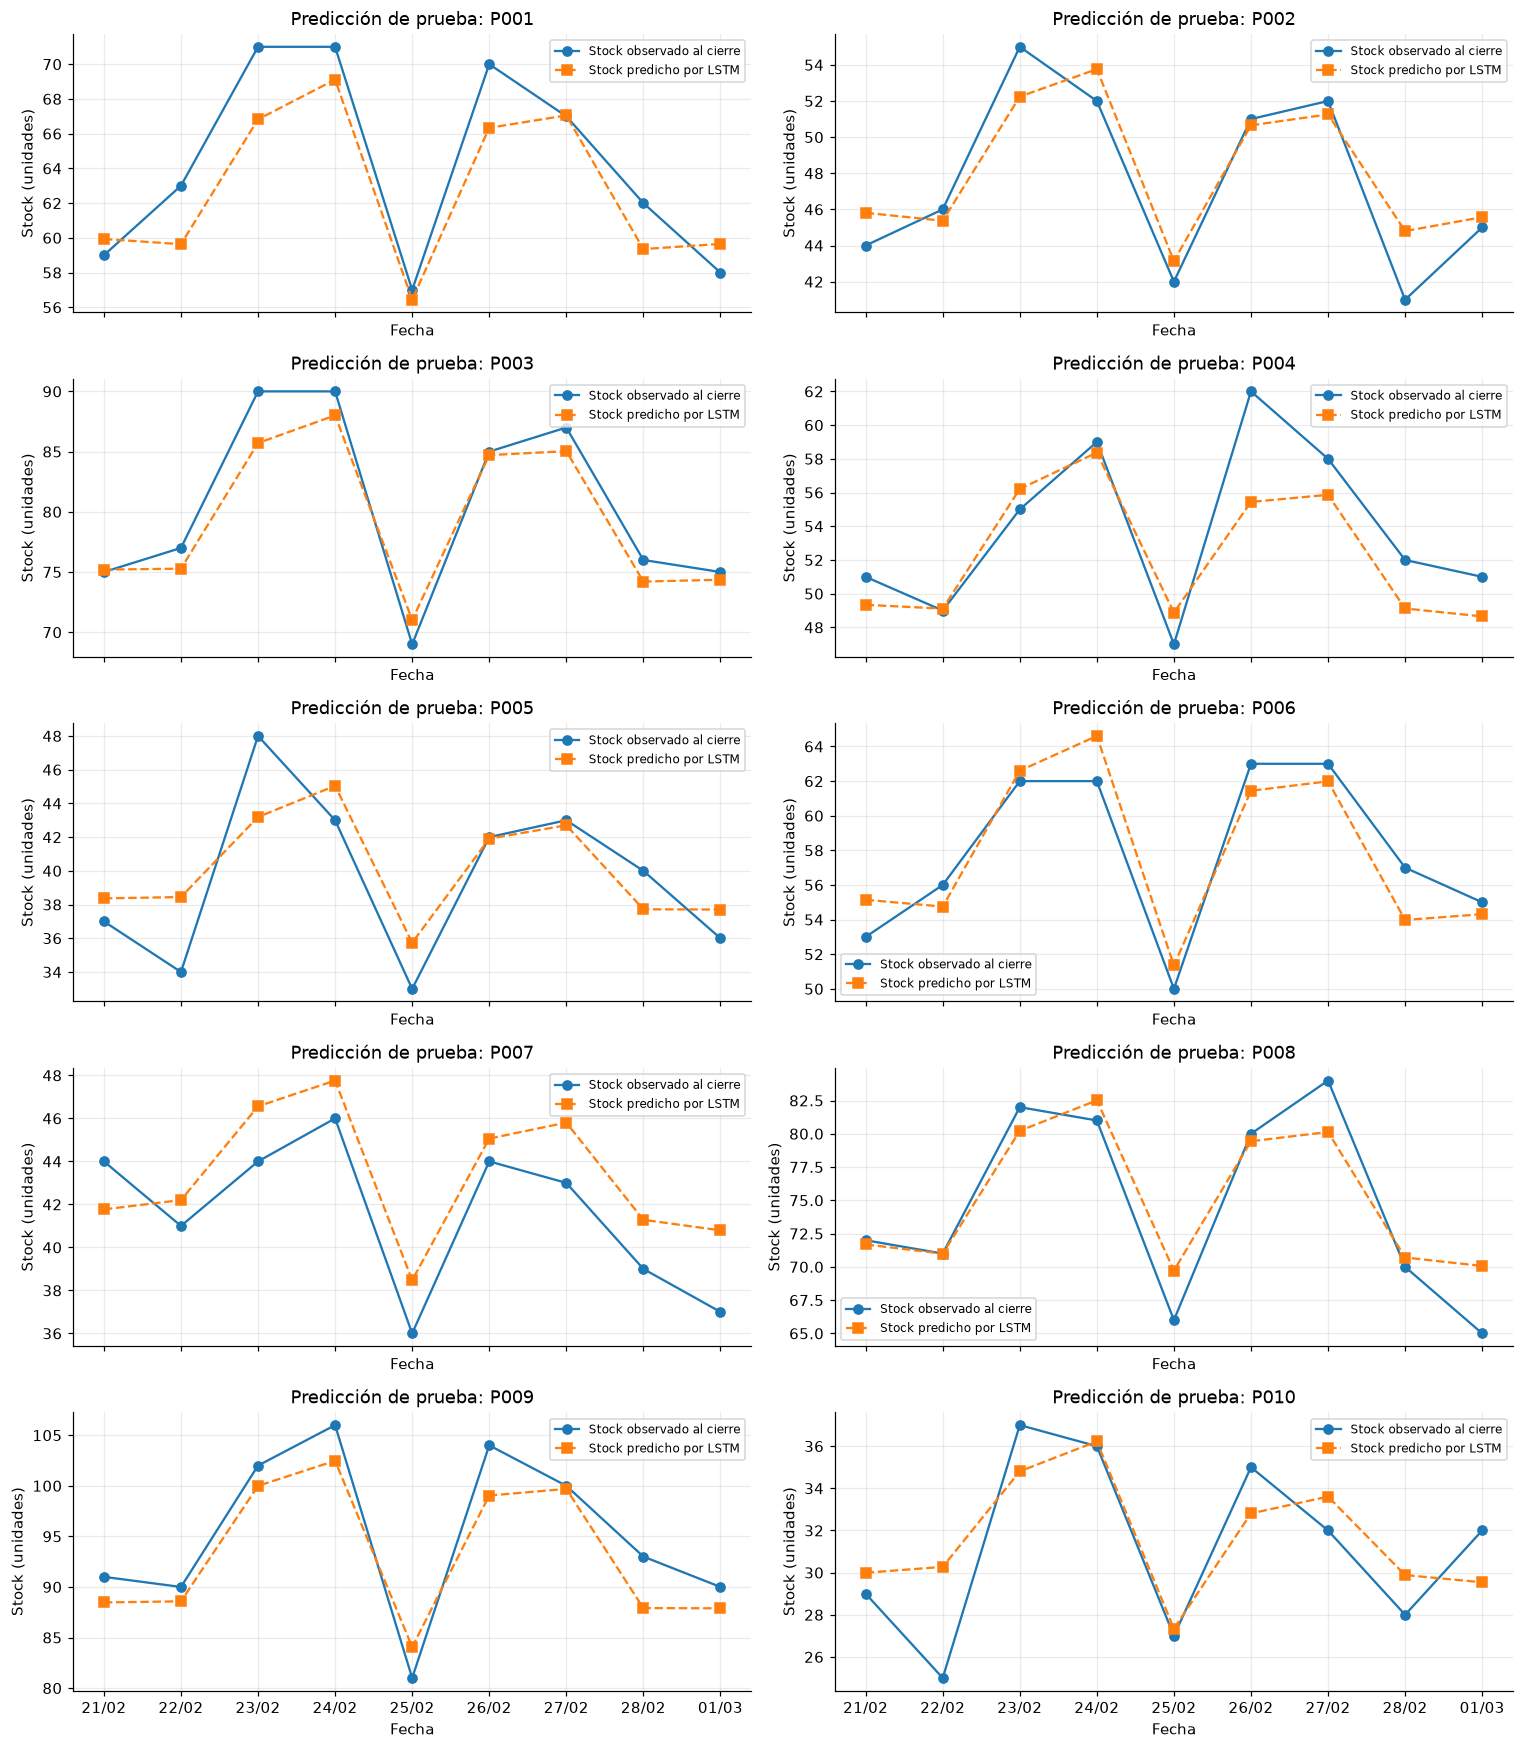

,MSE,RMSE,sesgo
product_id,,,
P001,6.2986,2.5097,-1.5186
P002,3.4558,1.8590,0.5118
P003,4.1124,2.0279,-1.1639
P004,7.7254,2.7795,-1.4442
P005,7.1739,2.6784,0.5349
P006,3.1324,1.7698,-0.0919
P007,5.6443,2.3758,1.7453
P008,6.7615,2.6003,0.4978
P009,9.9233,3.1501,-2.0990


Un sesgo positivo indica sobreestimación media y uno negativo indica subestimación. La tabla por producto permite identificar errores que un promedio general puede ocultar. Son solo nueve observaciones de prueba por producto, por lo que la estimación es limitada.

El mayor RMSE por producto corresponde a **P009**, con **3.1501 unidades de stock**. Esto permite identificar qué serie requiere más revisión.

In [13]:
fig, ejes = plt.subplots(5, 2, figsize=(14, 16), sharex=True)
for ax, (codigo, grupo) in zip(ejes.flat, predicciones_prueba.groupby("product_id")):
    ax.plot(grupo.fecha_venta, grupo.stock_cierre, "o-", label="Stock observado al cierre")
    ax.plot(grupo.fecha_venta, grupo.prediccion, "s--", label="Stock predicho por LSTM")
    ax.set(title=f"Predicción de prueba: {codigo}", xlabel="Fecha", ylabel="Stock (unidades)")
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%d/%m"))
    ax.legend(fontsize=8)
guardar_grafico("09_predicciones_por_producto")

errores = predicciones_prueba.assign(
    error=predicciones_prueba.prediccion - predicciones_prueba.stock_cierre)
por_producto = errores.groupby("product_id").apply(
    lambda grupo: pd.Series({"MSE": np.mean(grupo.error ** 2),
                            "RMSE": np.sqrt(np.mean(grupo.error ** 2)),
                            "sesgo": grupo.error.mean()}), include_groups=False)
display(por_producto.round(4))
por_producto.to_csv(TABLAS / "metricas_por_producto.csv")
display(Markdown("Un sesgo positivo indica sobreestimación media y uno negativo indica subestimación. "
                 "La tabla por producto permite identificar errores que un promedio general puede ocultar. "
                 "Son solo nueve observaciones de prueba por producto, por lo que la estimación es limitada."))

producto_mayor_error = por_producto.RMSE.idxmax()
display(Markdown(f"El mayor RMSE por producto corresponde a **{producto_mayor_error}**, "
                 f"con **{por_producto.loc[producto_mayor_error, 'RMSE']:.4f} unidades de stock**. "
                 "Esto permite identificar qué serie requiere más revisión."))


#### PREPARACIÓN DEL MODELO PARA USO FUTURO

Una vez finalizada la evaluación, se entrena una nueva red con los **60 días de historial**. Se conserva la configuración elegida mediante validación y se utiliza su mejor número de épocas. Los escaladores también se ajustan con todo el historial disponible.

El código guarda la red en formato Keras, los escaladores y un archivo de configuración dentro de la carpeta `modelos`, que se crea al ejecutar esta sección. Estos elementos permiten recuperar el modelo para consultas posteriores. Las métricas de prueba corresponden a los modelos evaluados con separación temporal; el reentrenamiento final se utiliza para las predicciones futuras.

In [14]:
N_DIAS = seleccionado["n_dias"]
USAR_INGENIERIA = seleccionado["ingenieria"]
datos_finales = preparar_secuencias(N_DIAS, USAR_INGENIERIA, usar_todo=True)
scaler_X = datos_finales["scaler_X"]
scaler_y = datos_finales["scaler_y"]
modelo_final = construir_modelo(N_DIAS, datos_finales["X"].shape[2])
modelo_final.fit(datos_por_lotes(datos_finales["X"], datos_finales["y"]),
                 epochs=seleccionado["mejor_epoca"], verbose=0, shuffle=False)
modelo_final.save(MODELOS / "stock_lstm.keras")
joblib.dump({"X": scaler_X, "y": scaler_y}, MODELOS / "escaladores.joblib")
configuracion_final = {
    "modelo": seleccionado["nombre"], "n_dias": N_DIAS,
    "ingenieria": USAR_INGENIERIA, "epocas": seleccionado["mejor_epoca"],
    "columnas": datos_finales["columnas"], "codigos": CODIGOS,
    "ultima_fecha": ultima_fecha.strftime("%Y-%m-%d"),
    "feriados_hipoteticos": FERIADOS.strftime("%Y-%m-%d").tolist(),
    "variable_objetivo": "stock_cierre",
    "reposicion": "diaria hasta el nivel observado",
    "niveles_reposicion": NIVELES_REPOSICION,
    "semilla": SEMILLA, "tensorflow": tf.__version__,
}
(MODELOS / "configuracion.json").write_text(
    json.dumps(configuracion_final, ensure_ascii=False, indent=2), encoding="utf-8")
print("Modelo y escaladores guardados. Ventana elegida:", N_DIAS, "días.")

Modelo y escaladores guardados. Ventana elegida: 7 días.


#### FUNCIONES DE PREDICCIÓN

Se implementan las dos consultas:

1. `predecir_stock_producto(product_id, fecha)` recibe un código y una fecha futura. Devuelve un número con el **stock al cierre predicho directamente por la LSTM**.
2. `predecir_stock_todos(fecha, productos=None)` recibe una fecha y devuelve una lista con el stock de todos los productos. También admite una lista de códigos para consultar un lote específico.

El vector sigue el orden de `CODIGOS`. Se presenta una tabla con la posición, el código y el nombre para mantener la correspondencia entre cada valor y su producto. La tabla de resultados se construye a partir del vector sin cambiar el retorno de las funciones.

Para fechas a varios días, la red predice el stock del día siguiente y se añade ese resultado al historial para continuar. Se conserva la **reposición diaria hasta el nivel observado**, igual que en los datos de entrenamiento. El stock puede subir o bajar entre días. La función no obtiene el stock restando una predicción de ventas.

El resultado se limita entre cero y el nivel disponible tras reponer. Se devuelve una cantidad continua esperada con dos decimales. No se fuerza el stock total a cero al vencer el lote actual: el escenario repone cada día y no contiene fechas de caducidad de los lotes futuros. Estas condiciones deben revisarse antes de utilizar el modelo con otra política de inventario.

In [15]:
mapa_productos = inventario[["product_id", "nombre"]].copy()
mapa_productos.insert(0, "posicion_vector", range(len(CODIGOS)))
display(mapa_productos)
mapa_productos.to_csv(TABLAS / "mapa_productos.csv", index=False)

def predecir_stock_producto(product_id, fecha):
    """Devuelve el stock de cierre estimado por la LSTM para un producto y fecha."""
    if not isinstance(product_id, str) or product_id not in CODIGOS:
        raise ValueError("Código desconocido. Códigos válidos: " + ", ".join(CODIGOS))
    if not isinstance(fecha, str) or re.fullmatch(r"\d{4}-\d{2}-\d{2}", fecha) is None:
        raise ValueError("La fecha debe tener formato YYYY-MM-DD.")
    try:
        objetivo = pd.Timestamp(fecha)
    except (ValueError, TypeError) as error:
        raise ValueError("La fecha no existe.") from error
    if objetivo <= ultima_fecha:
        raise ValueError(f"La fecha debe ser posterior a {ultima_fecha.date()}.")
    historial = ventas.loc[ventas.product_id == product_id,
                          ["product_id", "fecha_venta", "stock_cierre"]].copy()
    if len(historial) < N_DIAS:
        raise ValueError("No hay suficientes días para formar la ventana.")
    for dia in pd.date_range(ultima_fecha + pd.Timedelta(days=1), objetivo, freq="D"):
        variables = crear_variables(historial.tail(N_DIAS), USAR_INGENIERIA)
        Xnew = scaler_X.transform(variables).astype("float32")[None, :, :]
        stock = float(predecir_unidades(modelo_final, Xnew, scaler_y, [product_id])[0])
        if not np.isfinite(stock):
            raise ValueError("El modelo no produjo un stock finito.")
        historial = pd.concat([historial, pd.DataFrame([{
            "product_id": product_id, "fecha_venta": dia, "stock_cierre": stock,
        }])], ignore_index=True)
    return round(stock, 2)

def predecir_stock_todos(fecha, productos=None):
    """Devuelve un vector de stocks en el orden de CODIGOS o del lote indicado."""
    codigos = CODIGOS if productos is None else productos
    if not isinstance(codigos, (list, tuple)) or not codigos:
        raise ValueError("productos debe ser una lista no vacía de códigos.")
    return [predecir_stock_producto(codigo, fecha) for codigo in codigos]

fecha_ejemplo = (ultima_fecha + pd.Timedelta(days=1)).strftime("%Y-%m-%d")
individual = predecir_stock_producto("P001", fecha_ejemplo)
vector_stocks = predecir_stock_todos(fecha_ejemplo)
print(f"Stock de P001 para {fecha_ejemplo}: {individual} unidades")
print("Vector de stocks, en el orden de CODIGOS:", vector_stocks)
print("Lote P009, P001:", predecir_stock_todos(fecha_ejemplo, ["P009", "P001"]))
predicciones_todos = inventario[["product_id", "nombre", "unidad"]].copy()
predicciones_todos["fecha"] = fecha_ejemplo
predicciones_todos["stock_predicho"] = vector_stocks
display(predicciones_todos)
predicciones_todos.to_csv(TABLAS / "predicciones_futuras.csv", index=False)

fecha_varios_dias = (ultima_fecha + pd.Timedelta(days=3)).strftime("%Y-%m-%d")
print(f"Stock de P001 para {fecha_varios_dias}:", predecir_stock_producto("P001", fecha_varios_dias))

,posicion_vector,product_id,nombre
0,0,P001,Leche en botella
1,1,P002,Yogur individual
2,2,P003,Pan empacado
3,3,P004,Arroz en paquete
4,4,P005,Azúcar en paquete
5,5,P006,Aceite en botella
6,6,P007,Atún en lata
7,7,P008,Agua en botella
8,8,P009,Jugo en caja
9,9,P010,Detergente en bolsa


Stock de P001 para 2026-03-02: 69.64 unidades
Vector de stocks, en el orden de CODIGOS: [69.64, 53.38, 87.86, 57.51, 43.64, 63.72, 44.48, 80.95, 102.76, 37.08]


Lote P009, P001: [102.76, 69.64]


,product_id,nombre,unidad,fecha,stock_predicho
0,P001,Leche en botella,unidad,2026-03-02,69.64
1,P002,Yogur individual,unidad,2026-03-02,53.38
2,P003,Pan empacado,unidad,2026-03-02,87.86
3,P004,Arroz en paquete,unidad,2026-03-02,57.51
4,P005,Azúcar en paquete,unidad,2026-03-02,43.64
5,P006,Aceite en botella,unidad,2026-03-02,63.72
6,P007,Atún en lata,unidad,2026-03-02,44.48
7,P008,Agua en botella,unidad,2026-03-02,80.95
8,P009,Jugo en caja,unidad,2026-03-02,102.76
9,P010,Detergente en bolsa,unidad,2026-03-02,37.08


Stock de P001 para 2026-03-04: 70.29


#### COMPROBACIONES DE FUNCIONAMIENTO

Se verifica que el retorno individual sea un número y el general sea un vector, que su orden coincida con los códigos y que las existencias se mantengan dentro de los límites del escenario. También se comprueban entradas incorrectas, el avance recursivo y la recuperación del modelo guardado.

Para el día siguiente se compara la función con la salida directa de la red. Esto permite comprobar que devuelve stock predicho y no un saldo obtenido a partir de una predicción de ventas.

In [16]:
assert isinstance(individual, float)
assert isinstance(vector_stocks, list) and len(vector_stocks) == len(CODIGOS)
assert all(isinstance(stock, float) for stock in vector_stocks)
for codigo, stock in zip(CODIGOS, vector_stocks):
    assert stock == predecir_stock_producto(codigo, fecha_ejemplo)
    assert 0 <= stock <= NIVELES_REPOSICION[codigo]
assert predecir_stock_todos(fecha_ejemplo, ["P009", "P001"]) == [vector_stocks[8], vector_stocks[0]]
assert predecir_stock_todos(fecha_ejemplo, ["P001", "P001"]) == [individual, individual]

historial_p001 = ventas.loc[ventas.product_id == "P001"].tail(N_DIAS)
entrada_p001 = scaler_X.transform(crear_variables(historial_p001, USAR_INGENIERIA)).astype("float32")[None, :, :]
salida_directa = float(predecir_unidades(modelo_final, entrada_p001, scaler_y, ["P001"])[0])
assert individual == round(salida_directa, 2)
recursivo = predecir_stock_producto("P001", fecha_varios_dias)
assert np.isfinite(recursivo) and 0 <= recursivo <= NIVELES_REPOSICION["P001"]

def debe_fallar(funcion, *args):
    try:
        funcion(*args)
    except ValueError:
        return
    raise AssertionError(f"No se rechazó la entrada inválida: {args}")

debe_fallar(predecir_stock_producto, "P999", fecha_ejemplo)
debe_fallar(predecir_stock_producto, "P001", "2026-02-30")
debe_fallar(predecir_stock_producto, "P001", "02/03/2026")
debe_fallar(predecir_stock_producto, "P001", ultima_fecha.strftime("%Y-%m-%d"))
debe_fallar(predecir_stock_todos, fecha_ejemplo, [])
debe_fallar(predecir_stock_todos, fecha_ejemplo, ["P999"])

modelo_recuperado = tf.keras.models.load_model(MODELOS / "stock_lstm.keras", compile=False)
X_comprobacion = datos_finales["X"][:2]
assert np.allclose(modelo_final(X_comprobacion).numpy(), modelo_recuperado(X_comprobacion).numpy())
escaladores_recuperados = joblib.load(MODELOS / "escaladores.joblib")
assert np.allclose(escaladores_recuperados["y"].scale_, scaler_y.scale_)
print("Comprobaciones correctas: objetivo stock, secuencias, valor individual, vector ordenado, límites, recursión y modelo recuperado.")

Comprobaciones correctas: objetivo stock, secuencias, valor individual, vector ordenado, límites, recursión y modelo recuperado.


<div id="Conclusiones" style="color:#37475a; border-bottom: 7px solid orange; width: 100%; margin-bottom: 15px; padding-bottom: 2px"><h2>Conclusiones</h2> </div>

La preparación de los datos, la comparación de modelos y las consultas de inventario permiten relacionar el error de predicción con las decisiones de abastecimiento. Los resultados obtenidos se resumen a continuación.

In [17]:
conclusiones = f"""
1. Se preparó un historial sintético de **{len(inventario)} productos y {len(ventas)} observaciones**. El objetivo fue **stock_cierre**, obtenido de las existencias iniciales y las ventas observadas. Las entradas de la red usaron información anterior y calendario conocido.
2. Con la misma ventana de 1 día, la ingeniería de características cambió el MSE de prueba de **{mse_base:.4f} a {mse_fe:.4f} unidades²**; la ingeniería {verbo} el error en **{abs(cambio_fe):.2f} %**. Esta comparación permite evaluar el aporte del calendario y de las variables combinadas a la predicción de stock.
3. La configuración elegida por validación fue **{seleccionado['nombre']}**, con MSE de prueba **{fila_elegida.MSE_prueba:.4f} unidades²** y RMSE **{fila_elegida.RMSE_prueba:.4f} unidades de stock**. La persistencia obtuvo RMSE **{np.sqrt(mse_persistencia):.4f} unidades**. {'La LSTM seleccionada obtuvo menor error que la persistencia.' if fila_elegida.RMSE_prueba < np.sqrt(mse_persistencia) else 'La persistencia obtuvo menor o igual error; una red más compleja no garantiza mejores resultados.'}
4. La primera función devuelve un valor numérico de stock y la segunda devuelve un vector asociado al orden de códigos. Para P001, el stock al cierre estimado para **{fecha_ejemplo}** fue **{individual:.2f} unidades**. Las consultas se comprobaron contra la salida directa de la red.
5. Los pronósticos conservan la reposición diaria del escenario. El resultado permite comparar existencias futuras, pero debe validarse con más historial y con las políticas reales de reposición y caducidad antes de decidir compras. Las predicciones de varios días acumulan error y no tienen la misma evaluación que las consultas diarias de un paso.
"""
display(Markdown(conclusiones))


1. Se preparó un historial sintético de **10 productos y 600 observaciones**. El objetivo fue **stock_cierre**, obtenido de las existencias iniciales y las ventas observadas. Las entradas de la red usaron información anterior y calendario conocido.
2. Con la misma ventana de 1 día, la ingeniería de características cambió el MSE de prueba de **53.6126 a 7.2104 unidades²**; la ingeniería redujo el error en **86.55 %**. Esta comparación permite evaluar el aporte del calendario y de las variables combinadas a la predicción de stock.
3. La configuración elegida por validación fue **FE: 7 días**, con MSE de prueba **5.9867 unidades²** y RMSE **2.4468 unidades de stock**. La persistencia obtuvo RMSE **8.7299 unidades**. La LSTM seleccionada obtuvo menor error que la persistencia.
4. La primera función devuelve un valor numérico de stock y la segunda devuelve un vector asociado al orden de códigos. Para P001, el stock al cierre estimado para **2026-03-02** fue **69.64 unidades**. Las consultas se comprobaron contra la salida directa de la red.
5. Los pronósticos conservan la reposición diaria del escenario. El resultado permite comparar existencias futuras, pero debe validarse con más historial y con las políticas reales de reposición y caducidad antes de decidir compras. Las predicciones de varios días acumulan error y no tienen la misma evaluación que las consultas diarias de un paso.


<div id="Referencias" style="color:#37475a; border-bottom: 7px solid orange; width: 100%; margin-bottom: 15px; padding-bottom: 2px"><h2>Referencias</h2> </div>

1. Hurtado, R. (s. f.). *Aprendizaje profundo y series temporales*. Guía de práctica de laboratorio de Aprendizaje Automático.
2. Hurtado, R. (s. f.). *Redes neuronales recurrentes (RNN) y series temporales* [Cuaderno Jupyter]. [RNN_LSTM.ipynb](https://github.com/Remigiohurtadoins/MachineLearning-Engineering-Production-Portfolio/blob/main/8.Recurrent%20Neural%20Networks%20%28RNN%29%20and%20Time%20Series/RNN_LSTM.ipynb).
3. Keras. (s. f.). *LSTM layer*. [Documentación de la capa LSTM](https://keras.io/api/layers/recurrent_layers/lstm/).
4. Scikit-learn. (s. f.). *MinMaxScaler*. [Documentación de normalización](https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.MinMaxScaler.html).
5. Scikit-learn. (s. f.). *mean_squared_error*. [Documentación de la métrica MSE](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.mean_squared_error.html).
6. *Planificación de inventario y demanda de productos en supermercado*. (s. f.). Transcripción de clase de Aprendizaje Automático.